# Baseline phát hiện log bất thường với HDFS_v1


In [ ]:
from pathlib import Path
import json
import platform
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
)


In [12]:
DATA_DIR = Path("HDFS_v1")
OUTPUT_DIR = Path("hdfs_baseline_output")
SEED = 42
THRESHOLD = 0.5
FEATURES = [f"E{i}" for i in range(1, 30)]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Không tìm thấy thư mục: {DATA_DIR}")

versions = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
}
print("Phiên bản:", versions)

inventory = pd.DataFrame([
    {
        "file": str(p.relative_to(DATA_DIR)),
        "bytes": p.stat().st_size,
        "MiB": p.stat().st_size / 1024**2,
    }
    for p in DATA_DIR.rglob("*") if p.is_file()
])
display(inventory)


Phiên bản: {'python': '3.9.25', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'numpy': '2.0.2'}


,file,bytes,MiB
0,HDFS.log,1577982906,1504.881769
1,README.md,1347,0.001285
2,preprocessed\anomaly_label.csv,18637554,17.774157
3,preprocessed\Event_occurrence_matrix.csv,53099247,50.639388
4,preprocessed\Event_traces.csv,125412805,119.602971
5,preprocessed\HDFS.log_templates.csv,1607,0.001533
6,preprocessed\HDFS.npz,52907681,50.456697


Đọc dữ liệu và kiểm tra nhãn

Ghép bằng BlockId, không giả định hai file có cùng thứ tự hàng. Chỉ E1–E29 được dùng làm đầu vào. **Type, Label và BlockId không được đưa vào model.**

In [13]:
matrix = pd.read_csv(DATA_DIR / "preprocessed" / "Event_occurrence_matrix.csv")
labels = pd.read_csv(DATA_DIR / "preprocessed" / "anomaly_label.csv")
assert set(FEATURES).issubset(matrix.columns), "Thiếu cột sự kiện"
assert matrix["BlockId"].notna().all() and labels["BlockId"].notna().all()
assert not matrix["BlockId"].duplicated().any(), "Trùng BlockId trong ma trận"
assert not labels["BlockId"].duplicated().any(), "Trùng BlockId trong nhãn"
assert set(matrix["Label"].unique()) <= {"Success", "Fail"}
assert set(labels["Label"].unique()) <= {"Normal", "Anomaly"}

assert set(matrix.BlockId) == set(labels.BlockId), "Có block không ghép được nhãn"
joined = matrix.merge(labels, on="BlockId", how="left", sort=False, validate="one_to_one",
                      suffixes=("_matrix", "_truth"), indicator=True)
assert joined["_merge"].eq("both").all(), "Có block không ghép được nhãn"
y_matrix = joined["Label_matrix"].map({"Success": 0, "Fail": 1})
y = joined["Label_truth"].map({"Normal": 0, "Anomaly": 1}).to_numpy()
assert np.array_equal(y_matrix.to_numpy(), y), "Hai nguồn nhãn không khớp"
X = joined[FEATURES].apply(pd.to_numeric, errors="raise")
assert np.isfinite(X.to_numpy()).all(), "Có giá trị thiếu hoặc vô hạn"
assert (X.to_numpy() >= 0).all() and (X.to_numpy() % 1 == 0).all()
block_ids = joined["BlockId"].to_numpy()
audit = pd.DataFrame({
    "Kiểm tra": ["Số block", "Số đặc trưng", "BlockId trùng", "Giá trị thiếu trong X",
                  "Giá trị thiếu trong Type", "Vector đặc trưng trùng sau lần đầu", "Vector đặc trưng phân biệt"],
    "Kết quả": [len(X), len(FEATURES), joined.BlockId.duplicated().sum(), X.isna().sum().sum(),
                 joined.Type.isna().sum(), X.duplicated().sum(), len(X.drop_duplicates())]
})
display(audit)
display(joined[["BlockId", "Label_truth"] + FEATURES[:5]].head())


,Kiểm tra,Kết quả
0,Số block,575061
1,Số đặc trưng,29
2,BlockId trùng,0
3,Giá trị thiếu trong X,0
4,Giá trị thiếu trong Type,558223
5,Vector đặc trưng trùng sau lần đầu,574472
6,Vector đặc trưng phân biệt,589


,BlockId,Label_truth,E1,E2,E3,E4,E5
0,blk_-1608999687919862906,Normal,0,0,203,0,10
1,blk_7503483334202473044,Normal,0,2,1,0,3
2,blk_-3544583377289625738,Anomaly,0,0,203,0,3
3,blk_-9073992586687739851,Normal,0,3,0,0,3
4,blk_7854771516489510256,Normal,0,3,1,15,3



Chia phân tầng theo nhãn, xấp xỉ 70/15/15, seed 42. Một BlockId chỉ thuộc một tập.

,Lớp,Số block,Tỷ lệ %
0,Normal,558223,97.071963
1,Anomaly,16838,2.928037


,Tập,Normal,Anomaly,Tổng,Anomaly %
0,train,390755,11787,402542,2.928142
1,validation,83734,2525,86259,2.927231
2,test,83734,2526,86260,2.928356


Tỷ lệ Normal/Anomaly: 33.15 lần
Luôn đoán Normal: Accuracy = 97.07%, Recall Anomaly = 0%


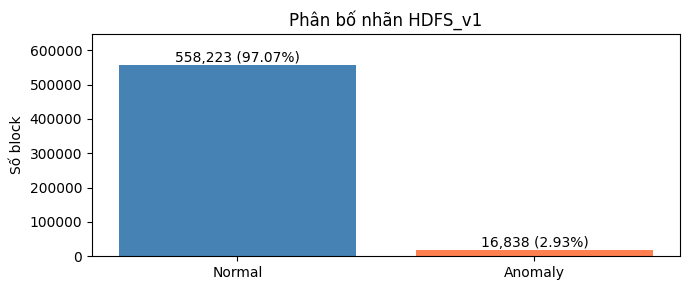

In [14]:
indices = np.arange(len(X))
train_idx, remaining_idx = train_test_split(indices, test_size=0.30, random_state=SEED, stratify=y)
val_idx, test_idx = train_test_split(remaining_idx, test_size=0.50, random_state=SEED, stratify=y[remaining_idx])
splits = {"train": train_idx, "validation": val_idx, "test": test_idx}
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(X)

class_counts = pd.Series(y).value_counts().reindex([0, 1])
class_table = pd.DataFrame({"Lớp": ["Normal", "Anomaly"], "Số block": class_counts.to_numpy(),
                            "Tỷ lệ %": class_counts.to_numpy() / len(y) * 100})
split_table = pd.DataFrame([
    {"Tập": name, "Normal": int(sum(y[ix] == 0)), "Anomaly": int(sum(y[ix] == 1)),
     "Tổng": len(ix), "Anomaly %": float(np.mean(y[ix]) * 100)}
    for name, ix in splits.items()
])
display(class_table); display(split_table)
print(f"Tỷ lệ Normal/Anomaly: {class_counts[0] / class_counts[1]:.2f} lần")
print(f"Luôn đoán Normal: Accuracy = {100 * np.mean(y == 0):.2f}%, Recall Anomaly = 0%")
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(class_table["Lớp"], class_table["Số block"], color=["steelblue", "coral"])
ax.set_ylabel("Số block"); ax.set_title("Phân bố nhãn HDFS_v1")
for i, row in class_table.iterrows():
    ax.text(i, row["Số block"], f'{row["Số block"]:,} ({row["Tỷ lệ %"]:.2f}%)', ha="center", va="bottom")
ax.set_ylim(0, class_counts.max() * 1.16)
plt.tight_layout(); plt.show()


## Train hai baseline
StandardScaler nằm trong Pipeline và chỉ fit trên train. Cấu hình A: class_weight=None. Cấu hình B: class_weight="balanced". Giữ cùng tham số và ngưỡng 0,5 để so sánh tác động của trọng số lớp.

In [15]:
models = {}; train_times = {}
for name, weight in [("LR", None), ("LR_balanced", "balanced")]:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000,
                                      class_weight=weight, random_state=SEED)),
    ])
    started = time.perf_counter()
    pipeline.fit(X.iloc[train_idx], y[train_idx])
    train_times[name] = time.perf_counter() - started
    models[name] = pipeline
    print(f"{name}: {train_times[name]:.2f} giây; số vòng tối ưu = {pipeline.named_steps['model'].n_iter_[0]}")


LR: 0.82 giây; số vòng tối ưu = 37
LR_balanced: 1.44 giây; số vòng tối ưu = 62


##  Mất cân bằng trước và sau xử lý
Trọng số w(c) = N_train / (2 × n_c). **Số mẫu và tỷ lệ lớp không thay đổi.** Chỉ mức đóng góp vào hàm mất mát thay đổi. Validation/test giữ nguyên phân bố.

,Lớp,Số mẫu trước,Số mẫu sau,Trọng số trước,Trọng số sau
0,Normal,390755,390755,1.0,0.515082
1,Anomaly,11787,11787,1.0,17.075677


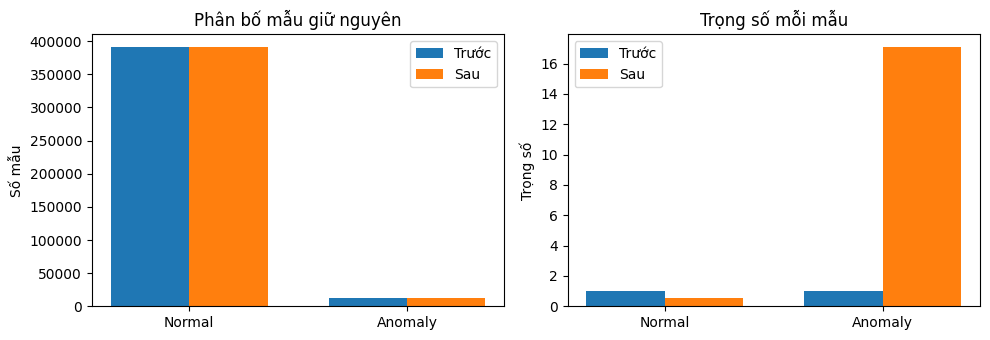

In [16]:
train_counts = np.bincount(y[train_idx], minlength=2)
weights = len(train_idx) / (2 * train_counts)
weight_table = pd.DataFrame({"Lớp": ["Normal", "Anomaly"], "Số mẫu trước": train_counts,
    "Số mẫu sau": train_counts, "Trọng số trước": [1., 1.], "Trọng số sau": weights})
display(weight_table)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
xpos = np.arange(2)
axs[0].bar(xpos - .18, train_counts, .36, label="Trước")
axs[0].bar(xpos + .18, train_counts, .36, label="Sau")
axs[0].set_ylabel("Số mẫu"); axs[0].set_title("Phân bố mẫu giữ nguyên")
axs[1].bar(xpos - .18, [1, 1], .36, label="Trước")
axs[1].bar(xpos + .18, weights, .36, label="Sau")
axs[1].set_ylabel("Trọng số"); axs[1].set_title("Trọng số mỗi mẫu")
for ax in axs:
    ax.set_xticks(xpos, ["Normal", "Anomaly"]); ax.legend()
plt.tight_layout(); plt.show()


## Chọn cấu hình bằng validation
F1 của lớp Anomaly là tiêu chí chọn model. Ngưỡng 0,5 cố định; không tối ưu trên test. AP được tính bằng average_precision_score, không phải tích phân hình thang của đường PR.

In [17]:
def evaluate(model, features, truth):
    probabilities = model.predict_proba(features)[:, 1]
    predictions = (probabilities >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, predictions, labels=[0, 1]).ravel()
    return {
        "Precision": precision_score(truth, predictions, zero_division=0),
        "Recall": recall_score(truth, predictions, zero_division=0),
        "F1": f1_score(truth, predictions, zero_division=0),
        "Accuracy": accuracy_score(truth, predictions),
        "AP": average_precision_score(truth, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }
val_results = pd.DataFrame({name: evaluate(model, X.iloc[val_idx], y[val_idx])
                            for name, model in models.items()}).T
best_name = val_results["F1"].idxmax()
display(val_results)
print("Model được chọn theo F1 validation:", best_name)


,Precision,Recall,F1,Accuracy,AP,TN,FP,FN,TP
LR,0.982799,0.995644,0.989180,0.999362,0.997975,83690.0,44.0,11.0,2514.0
LR_balanced,0.961158,0.999604,0.980004,0.998806,0.996169,83632.0,102.0,1.0,2524.0


Model được chọn theo F1 validation: LR


## Đánh giá test và confusion matrix
Test được dùng sau khi chọn cấu hình. Trình bày cả hai mô hình để thấy đánh đổi cảnh báo nhầm (FP) và bỏ sót (FN); không đổi quyết định chọn model theo test.

,Precision,Recall,F1,Accuracy,AP,TN,FP,FN,TP
LR,0.983984,0.997229,0.990562,0.999444,0.999354,83693.0,41.0,7.0,2519.0
LR_balanced,0.961187,1.000000,0.980210,0.998818,0.994987,83632.0,102.0,0.0,2526.0


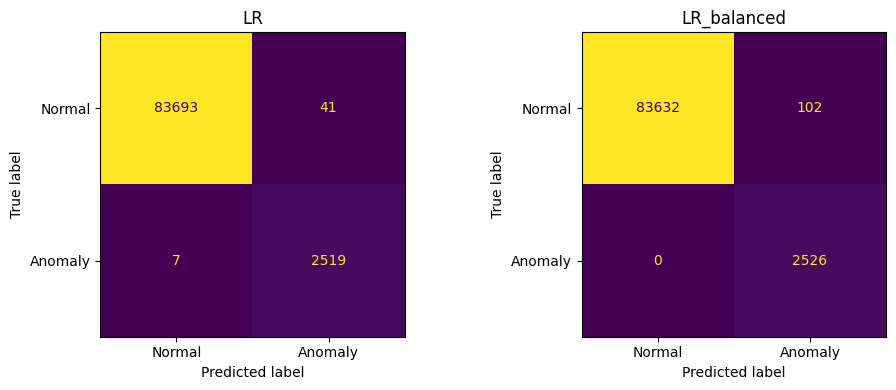

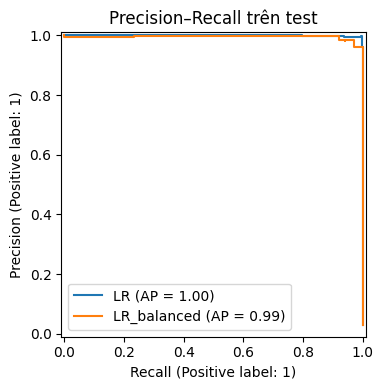

Baseline được chọn: LR
F1 test: 0.9906


In [18]:
test_results = pd.DataFrame({name: evaluate(model, X.iloc[test_idx], y[test_idx])
                             for name, model in models.items()}).T
display(test_results)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axs, models.items()):
    pred = (model.predict_proba(X.iloc[test_idx])[:, 1] >= THRESHOLD).astype(int)
    ConfusionMatrixDisplay.from_predictions(y[test_idx], pred, labels=[0, 1],
        display_labels=["Normal", "Anomaly"], ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 4))
for name, model in models.items():
    PrecisionRecallDisplay.from_predictions(y[test_idx], model.predict_proba(X.iloc[test_idx])[:, 1], name=name, ax=ax)
ax.set_title("Precision–Recall trên test")
plt.tight_layout(); plt.show()
print("Baseline được chọn:", best_name)
print("F1 test:", round(test_results.loc[best_name, "F1"], 4))


## Xem các trường hợp dự đoán sai
Nhãn dự đoán cho cả block; không suy ra rằng tất cả dòng bên trong một block bất thường đều là dòng lỗi.

In [19]:
best_model = models[best_name]
probs = best_model.predict_proba(X.iloc[test_idx])[:, 1]
preds = (probs >= THRESHOLD).astype(int)
predictions_table = pd.DataFrame({"BlockId": block_ids[test_idx], "y_true": y[test_idx],
    "y_pred": preds, "anomaly_score": probs})
false_positives = predictions_table.query("y_true == 0 and y_pred == 1").sort_values("anomaly_score", ascending=False)
false_negatives = predictions_table.query("y_true == 1 and y_pred == 0").sort_values("anomaly_score")
print("Ví dụ cảnh báo nhầm (FP):"); display(false_positives.head())
print("Ví dụ bỏ sót (FN):"); display(false_negatives.head())


Ví dụ cảnh báo nhầm (FP):


,BlockId,y_true,y_pred,anomaly_score
32724,blk_1344305487033986664,0,1,0.991418
29977,blk_4344613908503346582,0,1,0.991418
78426,blk_-1674706904979309223,0,1,0.991418
38891,blk_-3402760499772682003,0,1,0.987047
4702,blk_4621155940276908828,0,1,0.980493


Ví dụ bỏ sót (FN):


,BlockId,y_true,y_pred,anomaly_score
32624,blk_6656921730278789549,1,0,0.013689
12620,blk_-4068239347442694727,1,0,0.059643
66926,blk_-701924257856071885,1,0,0.082246
39721,blk_-7597453277224761233,1,0,0.119610
29188,blk_8838837797955603502,1,0,0.254824


In [20]:
artifact = {"pipeline": best_model, "features": FEATURES, "threshold": THRESHOLD,
            "selected_model": best_name, "seed": SEED, "versions": versions}
joblib.dump(artifact, OUTPUT_DIR / "hdfs_baseline.joblib")
for filename, frame in [("audit.csv", audit), ("class_distribution.csv", class_table),
                        ("split_distribution.csv", split_table), ("class_weights.csv", weight_table)]:
    frame.to_csv(OUTPUT_DIR / filename, index=False)
val_results.to_csv(OUTPUT_DIR / "validation_metrics.csv")
test_results.to_csv(OUTPUT_DIR / "test_metrics.csv")
predictions_table.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
split_names = np.empty(len(X), dtype=object)
for name, ix in splits.items(): split_names[ix] = name
pd.DataFrame({"BlockId": block_ids, "split": split_names, "label": y}).to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
(OUTPUT_DIR / "configuration.json").write_text(json.dumps({"seed": SEED, "threshold": THRESHOLD,
    "features": FEATURES, "selected_model": best_name, "versions": versions}, indent=2), encoding="utf-8")
print("Đã lưu kết quả vào:", OUTPUT_DIR.resolve())
# Kiểm tra lưu và nạp lại giữ nguyên dự đoán trên 5 block test.
loaded = joblib.load(OUTPUT_DIR / "hdfs_baseline.joblib")
example_X = X.iloc[test_idx[:5]][loaded["features"]]
loaded_scores = loaded["pipeline"].predict_proba(example_X)[:, 1]
assert np.allclose(loaded_scores, probs[:5])
print("Kiểm tra lưu/nạp model: đạt")


Đã lưu kết quả vào: C:\baseline_dsp\hdfs_baseline_output
Kiểm tra lưu/nạp model: đạt
